H3: ***AI tool usage has a statistically significant relationship with code quality***

In [1]:
%pip install matplotlib seaborn pandas


[notice] A new release of pip is available: 25.0.1 -> 26.1.1
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [3]:
BASE_DIR = Path().resolve().parent.parent / "output_files"
aiup_csv_path = BASE_DIR / "ai_usage_profile_eop.csv"
sqp_csv_path = BASE_DIR / "software_quality_profile.csv"

aiup_df = pd.read_csv(aiup_csv_path)
sqp_df = pd.read_csv(sqp_csv_path)

In [4]:
import pandas as pd
from pandas import col
from scipy import stats
import numpy as np

# Safe mode function
def safe_mode(x):
    if len(x) == 0:
        return np.nan
    return stats.mode(x, keepdims=False).mode if len(x) > 0 else np.nan

# List of AI metrics
ai_metrics = [
    "prob_human_droiddetect", "prob_machine_droiddetect",
    "prob_machine_refined_droiddetect", "prob_machine_generated_adversarial_droiddetect"
]

# Aggregation dictionary with multiple stats
agg_cols = {col: ["mean", "median", "std", "min", "max", safe_mode] for col in ai_metrics}

# Group by repository_id
aiup_final_product = aiup_df.groupby("repository_id").agg(agg_cols)

# Flatten multi-level columns
aiup_final_product.columns = [
    f"{col}_{func.__name__ if callable(func) else func}" for col, func in aiup_final_product.columns
]

final_columns = ["repository_id"] + [col for col in aiup_final_product.columns if col != "repository_id"]

# Reset index
aiup_final_product = aiup_final_product.reset_index()

aiup_final_product.drop(columns=[col for col in aiup_final_product.columns if col not in final_columns], inplace=True)

# Optional: round floats nicely
aiup_final_product = aiup_final_product.round(3)

display(aiup_final_product.head())
print(aiup_final_product.columns)
print(aiup_final_product.shape)

,repository_id,prob_human_droiddetect_mean,prob_human_droiddetect_median,prob_human_droiddetect_std,prob_human_droiddetect_min,prob_human_droiddetect_max,prob_human_droiddetect_safe_mode,prob_machine_droiddetect_mean,prob_machine_droiddetect_median,prob_machine_droiddetect_std,...,prob_machine_refined_droiddetect_std,prob_machine_refined_droiddetect_min,prob_machine_refined_droiddetect_max,prob_machine_refined_droiddetect_safe_mode,prob_machine_generated_adversarial_droiddetect_mean,prob_machine_generated_adversarial_droiddetect_median,prob_machine_generated_adversarial_droiddetect_std,prob_machine_generated_adversarial_droiddetect_min,prob_machine_generated_adversarial_droiddetect_max,prob_machine_generated_adversarial_droiddetect_safe_mode
0,2017_KDPRO-SINTEF_BowtieTool,0.449,0.398,0.322,0.001,0.954,0.901,0.124,0.063,0.171,...,0.007,0.001,0.049,0.007,0.418,0.348,0.330,0.006,0.955,0.045
1,2017_egrimstad_scalpel,0.406,0.325,0.316,0.003,0.915,0.003,0.177,0.098,0.205,...,0.008,0.001,0.056,0.001,0.410,0.333,0.321,0.010,0.910,0.010
2,2018_K-pro-SafeTec_Emergency-Response-CloudFun...,0.170,0.097,0.151,0.043,0.396,0.043,0.777,0.883,0.212,...,0.017,0.003,0.043,0.003,0.041,0.019,0.047,0.014,0.125,0.014
3,2018_K-pro-SafeTec_Emergency-Response-Portal,0.283,0.118,0.308,0.000,0.927,0.000,0.245,0.199,0.183,...,0.007,0.002,0.045,0.002,0.461,0.512,0.280,0.004,0.914,0.004
4,2018_Kpro11_Aqeous,0.384,0.328,0.293,0.001,0.906,0.020,0.342,0.256,0.230,...,0.010,0.001,0.064,0.006,0.263,0.200,0.220,0.004,0.808,0.060


Index(['repository_id', 'prob_human_droiddetect_mean',
       'prob_human_droiddetect_median', 'prob_human_droiddetect_std',
       'prob_human_droiddetect_min', 'prob_human_droiddetect_max',
       'prob_human_droiddetect_safe_mode', 'prob_machine_droiddetect_mean',
       'prob_machine_droiddetect_median', 'prob_machine_droiddetect_std',
       'prob_machine_droiddetect_min', 'prob_machine_droiddetect_max',
       'prob_machine_droiddetect_safe_mode',
       'prob_machine_refined_droiddetect_mean',
       'prob_machine_refined_droiddetect_median',
       'prob_machine_refined_droiddetect_std',
       'prob_machine_refined_droiddetect_min',
       'prob_machine_refined_droiddetect_max',
       'prob_machine_refined_droiddetect_safe_mode',
       'prob_machine_generated_adversarial_droiddetect_mean',
       'prob_machine_generated_adversarial_droiddetect_median',
       'prob_machine_generated_adversarial_droiddetect_std',
       'prob_machine_generated_adversarial_droiddetect_min',
  

In [5]:
import math

def plot_distributions_of_columns(aiup_final_product, skip_cols = []):
    sns.set_style("whitegrid")
    
    columns = aiup_final_product.columns
    
    metrics_to_plot = [col for col in columns if col not in skip_cols]
    n_metrics = len(metrics_to_plot)
    
    # Compute number of rows and columns for subplot grid
    n_cols = 2
    n_rows = math.ceil(n_metrics / n_cols)
    
    plt.figure(figsize=(6 * n_cols, 4 * n_rows))
    
    for i, metric in enumerate(metrics_to_plot, 1):
        plt.subplot(n_rows, n_cols, i)
        sns.histplot(aiup_final_product[metric], bins=20, kde=True)
        plt.title(f"Distribution of {metric}", fontsize=16)
    
    plt.tight_layout()
    plt.show()

In [6]:
# plot_distributions_of_columns(aiup_final_product, skip_cols=["repository_id"])

In [7]:
sqp_df["date"] = pd.to_datetime(sqp_df["date"], utc=True)

# Sort so latest commit is last
sqp_df_sorted = sqp_df.sort_values(["repository_id", "date"])

# Keep ONLY the last snapshot per repo
sqp_final_product = (
    sqp_df_sorted
    .groupby("repository_id")
    .tail(1)
    .reset_index(drop=True)
)

display(sqp_final_product.head())
print(sqp_final_product.shape)

,repository_id,snapshot_commit,date,bugs,classes,code_smells,cognitive_complexity,comment_lines,comment_lines_density,complexity,...,minor_ratio,info_ratio,security_ratio,reliability_ratio,maintainability_ratio,languages,issues_per_kloc,debt_per_kloc,complexity_per_kloc,quality_index
0,2017_KDPRO-SINTEF_BowtieTool,69b30a5a551aea56b4cf200f74e6fcf23abe2c1d,2017-11-21 09:33:58+00:00,44845,378.0,115263,33653.0,52507,25.5,28805.0,...,0.172426,0.000824,0.000006,0.316453,0.720478,"[{'val': 'web', 'count': 142370}, {'val': 'js'...",1041.793007,3914.201684,187.427612,4.75
1,2017_egrimstad_scalpel,7a29c5921df33ccdad8f21ac8336c06964740ad8,2017-11-23 11:29:47+00:00,6,10.0,138,158.0,511,10.1,511.0,...,0.381944,0.013889,0.000000,0.437500,0.979167,"[{'val': 'js', 'count': 142}, {'val': 'css', '...",31.606673,135.206321,112.159789,3.00
2,2018_K-pro-SafeTec_Emergency-Response-CloudFun...,aba72dbf1459c7712bd840543ac9d8fd82f690a1,2018-11-15 12:33:27+00:00,0,0.0,50,25.0,115,34.5,46.0,...,0.160000,0.000000,0.000000,0.040000,1.000000,"[{'val': 'js', 'count': 50}]",229.357798,1036.697248,211.009174,2.25
3,2018_K-pro-SafeTec_Emergency-Response-Portal,262d941fa61ac42b52439a90aab965e6ac397502,2018-11-15 12:17:06+00:00,5,12.0,335,179.0,289,4.1,482.0,...,0.147059,0.000000,0.000000,0.797059,0.991176,"[{'val': 'js', 'count': 340}]",50.169692,235.797551,71.122916,2.75
4,2018_Kpro11_Aqeous,78a06ec7166bbbb9bbd0a63cb4eddea5d9054f95,2018-11-27 16:12:20+00:00,907,0.0,3405,404.0,2650,10.2,516.0,...,0.295455,0.000000,0.000000,0.471243,0.788729,"[{'val': 'web', 'count': 3870}, {'val': 'js', ...",185.574109,747.460837,22.206920,3.00


(91, 60)


In [8]:
# plot_distributions_of_columns(sqp_final_product, skip_cols=["repository_id", "snapshot_commit"])

In [9]:
analysis_df = pd.merge(
    aiup_final_product,
    sqp_final_product,
    on="repository_id",
)

# print(analysis_df.columns)
print(analysis_df.shape)

aiup_ids = set(aiup_final_product['repository_id'])
sqp_ids  = set(sqp_final_product['repository_id'])

in_aiup_not_sqp = aiup_ids - sqp_ids
in_sqp_not_aiup = sqp_ids - aiup_ids
in_both         = aiup_ids & sqp_ids

print(f"Total in AIUP: {len(aiup_ids)}")
print(f"Total in SQP: {len(sqp_ids)}")
print(f"In AIUP but not SQP ({len(in_aiup_not_sqp)}): {in_aiup_not_sqp}")
print(f"In SQP but not AIUP ({len(in_sqp_not_aiup)}): {in_sqp_not_aiup}")
print(f"In both ({len(in_both)})")

(90, 84)
Total in AIUP: 91
Total in SQP: 91
In AIUP but not SQP (1): {'2020_Kundestyrt-Gruppe-10_Purefolio-backend'}
In SQP but not AIUP (1): {'2018_TDT4290-CiDev_api-gateway'}
In both (90)


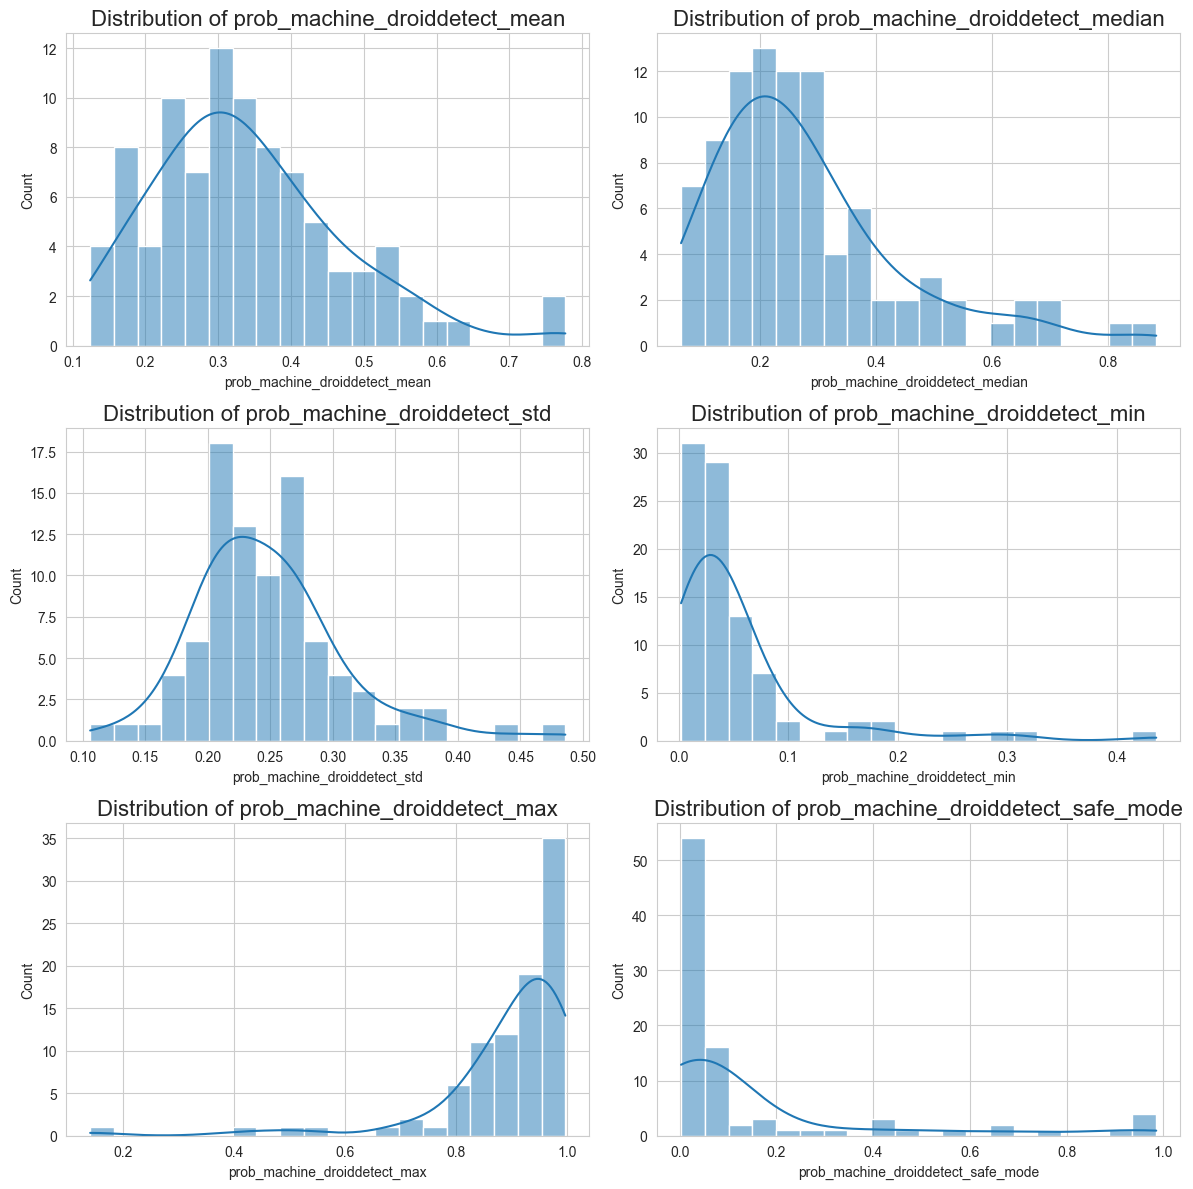

In [10]:
columns_to_show = [
    'prob_machine_droiddetect_mean',
       'prob_machine_droiddetect_median', 'prob_machine_droiddetect_std',
       'prob_machine_droiddetect_min', 'prob_machine_droiddetect_max',
       'prob_machine_droiddetect_safe_mode',
]
skip_cols = [col for col in analysis_df.columns if col not in columns_to_show]

plot_distributions_of_columns(aiup_final_product, skip_cols=skip_cols)

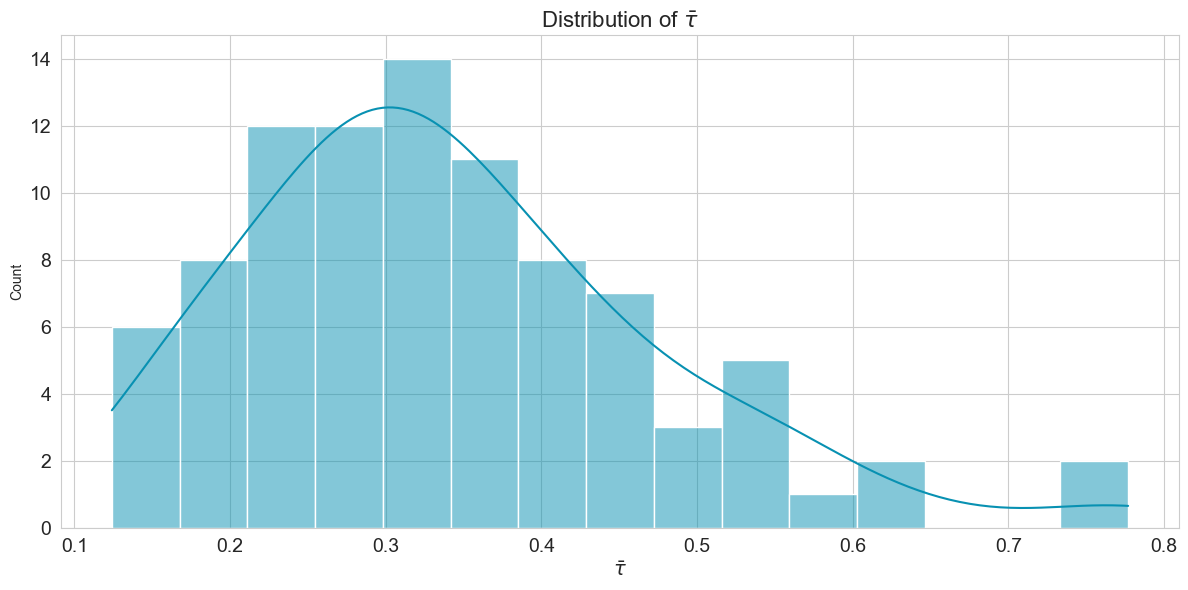

In [11]:
C_TEAL      = "#0891B2"   # teal        – seventh category
C_AI        = "#2563EB"   # blue        – AI-product group

def plot_droiddetect_mean(aiup_final_product, save_path=None):
    sns.set_style("whitegrid")
    plt.figure(figsize=(12, 6))
    sns.histplot(aiup_final_product['prob_machine_droiddetect_mean'], bins=15, kde=True, color=C_TEAL)
    plt.title(r"Distribution of $\bar{\tau}$", fontsize=16)
    plt.xlabel(r"$\bar{\tau}$", fontsize=14)
    plt.xticks(fontsize=14)
    plt.yticks(fontsize=14)
    
    plt.tight_layout()
    
    if(save_path is not None):
        plt.savefig(save_path, format='pdf')
    plt.show()

plot_droiddetect_mean(aiup_final_product, save_path="overleaf/H3_2.pdf")

In [12]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats

# ------------------------------------------------
# Metrics to evaluate
# ------------------------------------------------
def analyze_h3_high_ai_vs_low(df, quality_metrics):
   
    df = df.copy()

    # ------------------------------------------------
    # Mann-Whitney tests (non-parametric group difference)
    # ------------------------------------------------

    rows = []
    m = "sqale_debt_ratio"
    high = df[df["high_machine_droiddetect"] == True][m].dropna()
    low  = df[df["high_machine_droiddetect"] == False][m].dropna()
    print(f"High n={len(high)}, median={high.median():.3f}")
    print(f"Low  n={len(low)},  median={low.median():.3f}")
    
    for m in quality_metrics:

        quality_high_ai    = df[df["high_machine_droiddetect"] == True][m].dropna()
        quality_low_ai  = df[df["high_machine_droiddetect"] == False][m].dropna()

        if len(quality_high_ai) < 5 or len(quality_low_ai) < 5:
            continue

        # Shapiro-Wilk normality test per group
        _, shapiro_p_quality_high_ai    = stats.shapiro(quality_high_ai)    if len(quality_high_ai)    >= 3 else (None, None)
        _, shapiro_p_quality_low_ai = stats.shapiro(quality_low_ai) if len(quality_low_ai) >= 3 else (None, None)
        is_normally_distributed = shapiro_p_quality_high_ai > 0.05 and shapiro_p_quality_low_ai > 0.05

        # Mann-Whitney U: quality ~ ai_product_project
        n1 = quality_high_ai
        n2 = quality_low_ai

        mw_u_quality_high_ai,  mw_p   = stats.mannwhitneyu(n1, n2, alternative='two-sided')
        mw_u_quality_low_ai    = len(n1) * len(n2) - mw_u_quality_high_ai
        min_u = min(mw_u_quality_high_ai, mw_u_quality_low_ai)
        r_mw = 1 - (2 * min_u) / (len(n1) * len(n2))        
        

        rows.append({
            "metric":                           m,
            "mean_quality(high_machine_droiddetect)":         round(quality_high_ai.mean(),    3),
            "median_quality(high_machine_droiddetect)":       round(quality_high_ai.median(),  3),
            "mean_quality(low_machine_droiddetect)":      round(quality_low_ai.mean(),   3),
            "median_quality(low_machine_droiddetect)":    round(quality_low_ai.median(), 3),
            "U(quality|high_machine_droiddetect)":            round(mw_u_quality_high_ai, 1),
            "U(quality|low_machine_droiddetect)":         round(mw_u_quality_low_ai, 1),
            "p_mw(quality|high_machine_droiddetect)":         round(mw_p, 4),
            "r_mw(quality|high_machine_droiddetect)":      round(r_mw, 3),
            "Normal?":                          "Yes" if is_normally_distributed else "No",
        })

    stats_table_quality_by_ai_product = pd.DataFrame(rows)

    return {
        "repo_df":              df,
        "mannwhitney_results":  stats_table_quality_by_ai_product,
    }



In [13]:
quality_metrics = [
        "bugs", "classes", "code_smells", 
        "cognitive_complexity", "comment_lines", "comment_lines_density", 
        "complexity", "coverage", "duplicated_blocks", "duplicated_files", 
        "duplicated_lines", "duplicated_lines_density", "files", "functions", 
        "lines", "lines_to_cover", "ncloc", "open_issues", "reliability_rating", 
        "reliability_remediation_effort", "security_hotspots", "security_rating", 
        "security_remediation_effort", "security_review_rating", "sqale_debt_ratio", 
        "sqale_index", "sqale_rating", "statements", "tests", "uncovered_lines", 
        "violations", "vulnerabilities", "n_blocker", "n_critical", "n_major", 
        "n_minor", "n_info", "n_security", "n_reliability", "n_maintainability", 
        "n_consistent", "n_intentional", "n_adaptable", "n_responsible", 
        "total_issues_per_kloc", "critical_plus_blocker_ratio", "major_ratio", 
        "minor_ratio", "info_ratio", "security_ratio", "reliability_ratio", 
        "maintainability_ratio"
    ]

METRIC_LABELS = {
    "bugs":                     "Bugs",
    "code_smells":              "Code Smells",
    "cognitive_complexity":     "Cognitive Complexity",
    "complexity":               "Cyclomatic Complexity",
    "duplicated_lines_density": "Duplication Density (%)",
    "vulnerabilities":          "Vulnerabilities",
    "sqale_debt_ratio":         "Technical Debt Ratio (%)",
    "total_issues_per_kloc":    "Issues per kLoC",
    "classes":                  "Classes",
    "comment_lines":            "Comment Lines",
    "comment_lines_density":    "Comment Lines Density (%)",
    "files":                    "Files",
    "functions":                "Functions",
    "lines":                    "Lines",
    "lines_to_cover":           "Lines to Cover",
    "ncloc":                    "Non-Comment Lines of Code",
    "open_issues":              "Open Issues",
    "reliability_rating":       "Reliability Rating",
    "reliability_remediation_effort": "Reliability Remediation Effort",
    "security_hotspots":        "Security Hotspots",
    "security_rating":         "Security Rating",
    "security_remediation_effort": "Security Remediation Effort",
    "security_review_rating":   "Security Review Rating",
    "sqale_index":             "Technical Debt (days)",
    "sqale_rating":            "Technical Debt Rating",
    "statements":              "Statements",
    "tests":                   "Tests",
    "uncovered_lines":         "Uncovered Lines",
    "violations":              "Violations",
    "n_blocker":               "Blocker Issues",
    "n_critical":              "Critical Issues",
    "n_major":                 "Major Issues",
    "n_minor":                 "Minor Issues",
    "n_info":                  "Info Issues",
    "n_security":              "Security Issues",
    "n_reliability":           "Reliability Issues",
    "n_maintainability":       "Maintainability Issues",
    "n_consistent":            "Consistent Issues",
    "n_intentional":           "Intentional Issues",
    "n_adaptable":            "Adaptable Issues",
    "n_responsible":          "Responsible Issues",
    "critical_plus_blocker_ratio": "Critical + Blocker Issues Ratio",
    "major_ratio":            "Major Issues Ratio (%)",
    "minor_ratio":            "Minor Issues Ratio (%)",
    "info_ratio":             "Info Issues Ratio (%)",
    "security_ratio":         "Security Issues Ratio (%)",
    "reliability_ratio":      "Reliability Issues Ratio (%)",
    "maintainability_ratio":  "Maintainability Issues Ratio (%)",
}


In [14]:
# ── Universal colour palette ──────────────────────────────────────────────────
# All colours tested for mutual harmony and sufficient contrast on white/light bg

# Group / category colours
C_AI        = "#2563EB"   # blue        – AI-product group
C_DEV       = "#575B64"   # slate grey  – no AI-product group
C_ORANGE    = "#EA6C00"   # orange      – third category / accent
C_GREEN     = "#0F8C4A"   # green       – fourth category
C_RED       = "#CC1F1F"   # red         – fifth category
C_PURPLE    = "#6D28D9"   # violet      – sixth category
C_TEAL      = "#0891B2"   # teal        – seventh category

# A ready-made ordered list for cycling through groups
CATEGORY_COLORS = [C_AI, C_ORANGE, C_GREEN, C_RED, C_PURPLE, C_TEAL, C_DEV]

# Significance / annotation colours
C_SIG       = "#0F8C4A"   # green  – statistically significant  (matches C_GREEN)
C_TREND     = "#EA6C00"   # amber  – trending                   (matches C_ORANGE)
C_NS        = "#BFC8D7"   # light grey – not significant

# Direction colours (right-panel bars)
C_POS       = "#2563EB"   # blue – AI group higher              (matches C_AI)
C_NEG       = "#CC1F1F"   # red  – no-AI group higher           (matches C_RED)

# Text colours
C_TEXT      = "#111827"   # near-black – significant rows / primary labels
C_TEXT_NS   = "#6B7280"   # mid grey   – non-significant rows
C_TEXT_SOFT = "#9CA3AF"   # light grey – annotations / secondary labels

# Row / background shading
C_ROW_SIG   = "#F0FDF4"   # very light green – significant row highlight
C_ROW_TREND = "#FFF7ED"   # very light amber – trending row highlight
C_ROW_ALT   = "#F9FAFB"   # off-white        – alternating row stripe
C_ROW       = "#FFFFFF"   # white            – default row
C_ROW_SHADING = "#F9FAFB"  # light grey for alternating row shading

# Hatch patterns paired with CATEGORY_COLORS for B&W printing
CATEGORY_HATCHES = ["", "///", "...", "xxx", "\\\\\\", "|||", "+++"]

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D

def _stars(p):
    if p < 0.001: return "***"
    if p < 0.01:  return "**"
    if p < 0.05:  return "*"
    if p < 0.10:  return "†"
    return ""
 
def _effect_size(r):
    if pd.isna(r):
        return "N/A"
    if abs(r) < 0.1:
        return "Negligible"
    elif abs(r) < 0.3:
        return "Small"
    elif abs(r) < 0.5:
        return "Medium"
    else:
        return "Large"

def _sig_color(p):
    if p < 0.05:  return C_SIG
    if p < 0.10:  return C_TREND
    return C_NS
 
def _label(m):
    return METRIC_LABELS.get(m, m.replace("_", " ").title())
 
def visualize_mw_results(df, high_threshold, alpha=0.05, measure="median", save_path=None):
    if(measure not in ["median", "mean"]):
        raise ValueError("Measure must be 'median' or 'mean'")
    
    df = df.copy().sort_values("p_mw(quality|high_machine_droiddetect)", ascending=False).reset_index(drop=True)
    N  = len(df)
    y  = np.arange(N)

    if(measure == "mean"):
        df["pct_diff"] = (
            (df["mean_quality(high_machine_droiddetect)"] - df["mean_quality(low_machine_droiddetect)"])
            / df["mean_quality(low_machine_droiddetect)"].abs().replace(0, np.nan) * 100
        )
  
    if(measure == "median"):
        df["pct_diff"] = (
            (df["median_quality(high_machine_droiddetect)"] - df["median_quality(low_machine_droiddetect)"])
            / df["median_quality(low_machine_droiddetect)"].abs().replace(0, np.nan) * 100
        )

    fig, (ax_bar, ax_pct) = plt.subplots(
        1, 2, figsize=(13, max(4.5, N * 0.7 + 2.0)),
        gridspec_kw={"width_ratios": [2, 1.2], "wspace": 0.06}, dpi=300,
    )
    fig.subplots_adjust(left=0.26, right=0.97, top=0.91, bottom=0.13)

    
    # ── Row shading ───────────────────────────────────────────────────────────
    for ax in (ax_bar, ax_pct):
        for i in range(N):
            p = df.loc[i, "p_mw(quality|high_machine_droiddetect)"]
            bg = C_ROW_SHADING if p < alpha else (C_ROW if p < 0.10 else None)
            if i % 2 == 0 and bg is None:
                bg = C_ROW
            if bg:
                ax.axhspan(i - 0.5, i + 0.5, color=bg, zorder=0)
 
    # ════════════════════════════════════════════════════════════════════════
    # LEFT PANEL — side-by-side horizontal bar chart of raw medians
    # ════════════════════════════════════════════════════════════════════════
    bar_h = 0.35

    # Normalise per metric so bars are comparable across metrics
    for i, row in df.iterrows():
        if measure == "median":
            m_ai  = row["median_quality(high_machine_droiddetect)"]
            m_dev = row["median_quality(low_machine_droiddetect)"]
        else:  # measure == "mean"
            m_ai  = row["mean_quality(high_machine_droiddetect)"]
            m_dev = row["mean_quality(low_machine_droiddetect)"]

        scale = max(abs(m_ai), abs(m_dev), 1e-9)

        p   = row["p_mw(quality|high_machine_droiddetect)"]
        r = row["r_mw(quality|high_machine_droiddetect)"]
        fad = 1.0 if p < alpha else 0.50
        sc  = _sig_color(p)

        # Low DroidDetect bar (lower slot)
        ax_bar.barh(i - bar_h / 2, m_dev / scale, height=bar_h,
                    color=C_TEAL, alpha=fad, linewidth=0, zorder=2, hatch=CATEGORY_HATCHES[1])
        # High DroidDetect bar (upper slot)
        ax_bar.barh(i + bar_h / 2, m_ai  / scale, height=bar_h,
                    color=C_ORANGE,  alpha=fad, linewidth=0, zorder=2, hatch=CATEGORY_HATCHES[0])

        # Raw value labels
        ax_bar.text(m_dev / scale + 0.02, i - bar_h / 2,
                    f"{m_dev:.3g}", va="center", ha="left",
                    fontsize=10, color=C_TEAL, alpha=fad)
        ax_bar.text(m_ai  / scale + 0.02, i + bar_h / 2,
                    f"{m_ai:.3g}",  va="center", ha="left",
                    fontsize=10, color=C_ORANGE,  alpha=fad)

        # Significance annotation
        stars = _stars(p)
        p_val = f"{p:.3f}" if p >= 0.001 else "< .001"
        p_str = f"$p_{{MW}} = {p_val}$"
        r_str = f"$r_{{MW}} = {r:.3f}$"
        
        label = f"{stars} {p_str}\n{r_str}" if stars else f"{p_str}\n{r_str}"
        
        ax_bar.text(1.32, i, label,
                    va="center", ha="left",
                    fontsize=12,
                    fontweight="bold" if p < alpha else "normal",
                    color=sc,
                    usetex=False)
        
        # Metric label
        ax_bar.text(-0.04, i, _label(row["metric"]),
                    va="center", ha="right", fontsize=14,
                    color=C_TEXT if p < alpha else C_TEXT_NS)
        
    # Column headers
    if(measure == "median"):
        ax_bar.text(0.5, N - 0.1, "Normalised median (per metric)",
                    va="bottom", ha="center", fontsize=14, color=C_TEXT)
    if(measure == "mean"):
        ax_bar.text(0.5, N - 0.1, "Normalised mean (per metric)",
                    va="bottom", ha="center", fontsize=14, color=C_TEXT)
    ax_bar.text(1.12, N - 0.1, r"Significance ($p_{MW} < .10$)",
                va="bottom", ha="left",  fontsize=14, color=C_TEXT)

    ax_bar.axvline(0, color=C_TEXT, lw=0.8, linestyle="--", zorder=3)
    ax_bar.set_xlim(-0.05, 1.85)
    ax_bar.set_ylim(-0.6, N - 0.1)
    ax_bar.axis("off")

    # ════════════════════════════════════════════════════════════════════════
    # RIGHT PANEL — % median difference
    # ════════════════════════════════════════════════════════════════════════
    for i, row in df.iterrows():
        p   = row["p_mw(quality|high_machine_droiddetect)"]
        pct = row["pct_diff"]
        if pd.isna(pct):
            continue

        col = C_POS if pct >= 0 else C_NEG
        fad = 1.0 if p < alpha else 0.50

        ax_pct.barh(i, pct, height=0.5,
                    color=col, alpha=fad,
                    linewidth=0.5, edgecolor=col, zorder=2)

        offset = 1.0 if pct >= 0 else -1.0
        ax_pct.text(pct + offset, i,
                    f"{pct:+.1f}%",
                    va="center", ha="left" if pct >= 0 else "right",
                    fontsize=14, color=col, alpha=fad)

    ax_pct.axvline(0, color=C_TEXT, lw=0.9, linestyle="--", zorder=3)
    xlim = max(abs(df["pct_diff"].dropna()).max() * 1.5, 15)
    ax_pct.set_xlim(-xlim, xlim)
    ax_pct.set_ylim(-0.6, N - 0.1)
    ax_pct.set_yticks(y)
    ax_pct.set_yticklabels([])
    
    if(measure == "median"):
        ax_pct.set_xlabel("% difference in median\n(High DroidDetect - Low DroidDetect)", fontsize=14)
    if(measure == "mean"):
        ax_pct.set_xlabel("% difference in mean\n(High DroidDetect - Low DroidDetect)", fontsize=14)
        
    ax_pct.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:+.0f}%"))
    ax_pct.spines["top"].set_visible(False)
    ax_pct.spines["right"].set_visible(False)
    ax_pct.spines["left"].set_visible(False)
    ax_pct.tick_params(left=False)

    # ── Legend ────────────────────────────────────────────────────────────────
    handles = [
        mpatches.Patch(facecolor=C_ORANGE, edgecolor=C_TEXT, label="High DroidDetect group"),
        mpatches.Patch(facecolor=C_TEAL,   edgecolor=C_TEXT, hatch="////", linewidth=0.5, label="Low DroidDetect group"),
        mpatches.Patch(facecolor=C_POS,    label="High DroidDetect higher (right panel)"),
        mpatches.Patch(facecolor=C_NEG,    label="Low DroidDetect higher (right panel)"),
    ]
        
    fig.legend(handles=handles, loc="lower center", ncol=2,
               fontsize=14, 
               edgecolor=C_TEXT_NS, bbox_to_anchor=(0.58, -0.10))

    fig.suptitle(
        f"High DroidDetect vs. Low DroidDetect Projects on Quality (sorted by MW p-value)\n(threshold: $\\bar\\tau >$ {high_threshold} for High DroidDetect group)",
    fontsize=16, fontweight="normal", x=0.58, y=1.02,
    )

    if(save_path):
        plt.savefig(save_path, format="pdf", bbox_inches="tight")
        
    plt.show()

In [16]:
two_group_df = analysis_df.copy()

high_threshold = 0.5

two_group_df["high_machine_droiddetect"] = two_group_df["prob_machine_droiddetect_mean"] > high_threshold
print(len(two_group_df[two_group_df["high_machine_droiddetect"] == True]), "projects with High Machine DroidDetect")
print(len(two_group_df[two_group_df["high_machine_droiddetect"] == False]), "projects with Low Machine DroidDetect")

h3_results = analyze_h3_high_ai_vs_low(two_group_df, quality_metrics)

df = h3_results["mannwhitney_results"]

12 projects with High Machine DroidDetect
78 projects with Low Machine DroidDetect
High n=12, median=0.750
Low  n=78,  median=0.300


/Users/magnus/iCloud Drive (Archive)/NTNU/Semester 10/TDT4900/pgs_v2/.venv/lib/python3.11/site-packages/scipy/stats/_axis_nan_policy.py:592: UserWarning: scipy.stats.shapiro: Input data has range zero. The results may not be accurate.
  res = hypotest_fun_out(*samples, **kwds)
/Users/magnus/iCloud Drive (Archive)/NTNU/Semester 10/TDT4900/pgs_v2/.venv/lib/python3.11/site-packages/scipy/stats/_axis_nan_policy.py:592: UserWarning: scipy.stats.shapiro: Input data has range zero. The results may not be accurate.
  res = hypotest_fun_out(*samples, **kwds)


,metric,mean_quality(high_machine_droiddetect),median_quality(high_machine_droiddetect),mean_quality(low_machine_droiddetect),median_quality(low_machine_droiddetect),U(quality|high_machine_droiddetect),U(quality|low_machine_droiddetect),p_mw(quality|high_machine_droiddetect),r_mw(quality|high_machine_droiddetect),Normal?
5,comment_lines_density,12.475,10.900,8.547,6.800,610.0,326.0,0.0930,0.303,No
6,complexity,355.083,89.000,1397.893,395.000,307.0,593.0,0.0794,0.318,No
12,files,112.000,10.000,107.321,72.000,299.5,636.5,0.0461,0.360,No
13,functions,170.250,33.500,549.093,225.000,281.0,619.0,0.0381,0.376,No
14,lines,7632.333,1734.500,27413.718,4293.500,341.0,595.0,0.1332,0.271,No
16,ncloc,5893.667,593.500,9083.154,3366.500,316.0,620.0,0.0721,0.325,No
24,sqale_debt_ratio,0.992,0.750,0.662,0.300,669.5,266.5,0.0161,0.431,No
43,total_issues_per_kloc,61.090,42.013,44.329,21.806,620.0,316.0,0.0721,0.325,No
44,critical_plus_blocker_ratio,0.216,0.144,0.121,0.058,630.5,305.5,0.0538,0.347,No


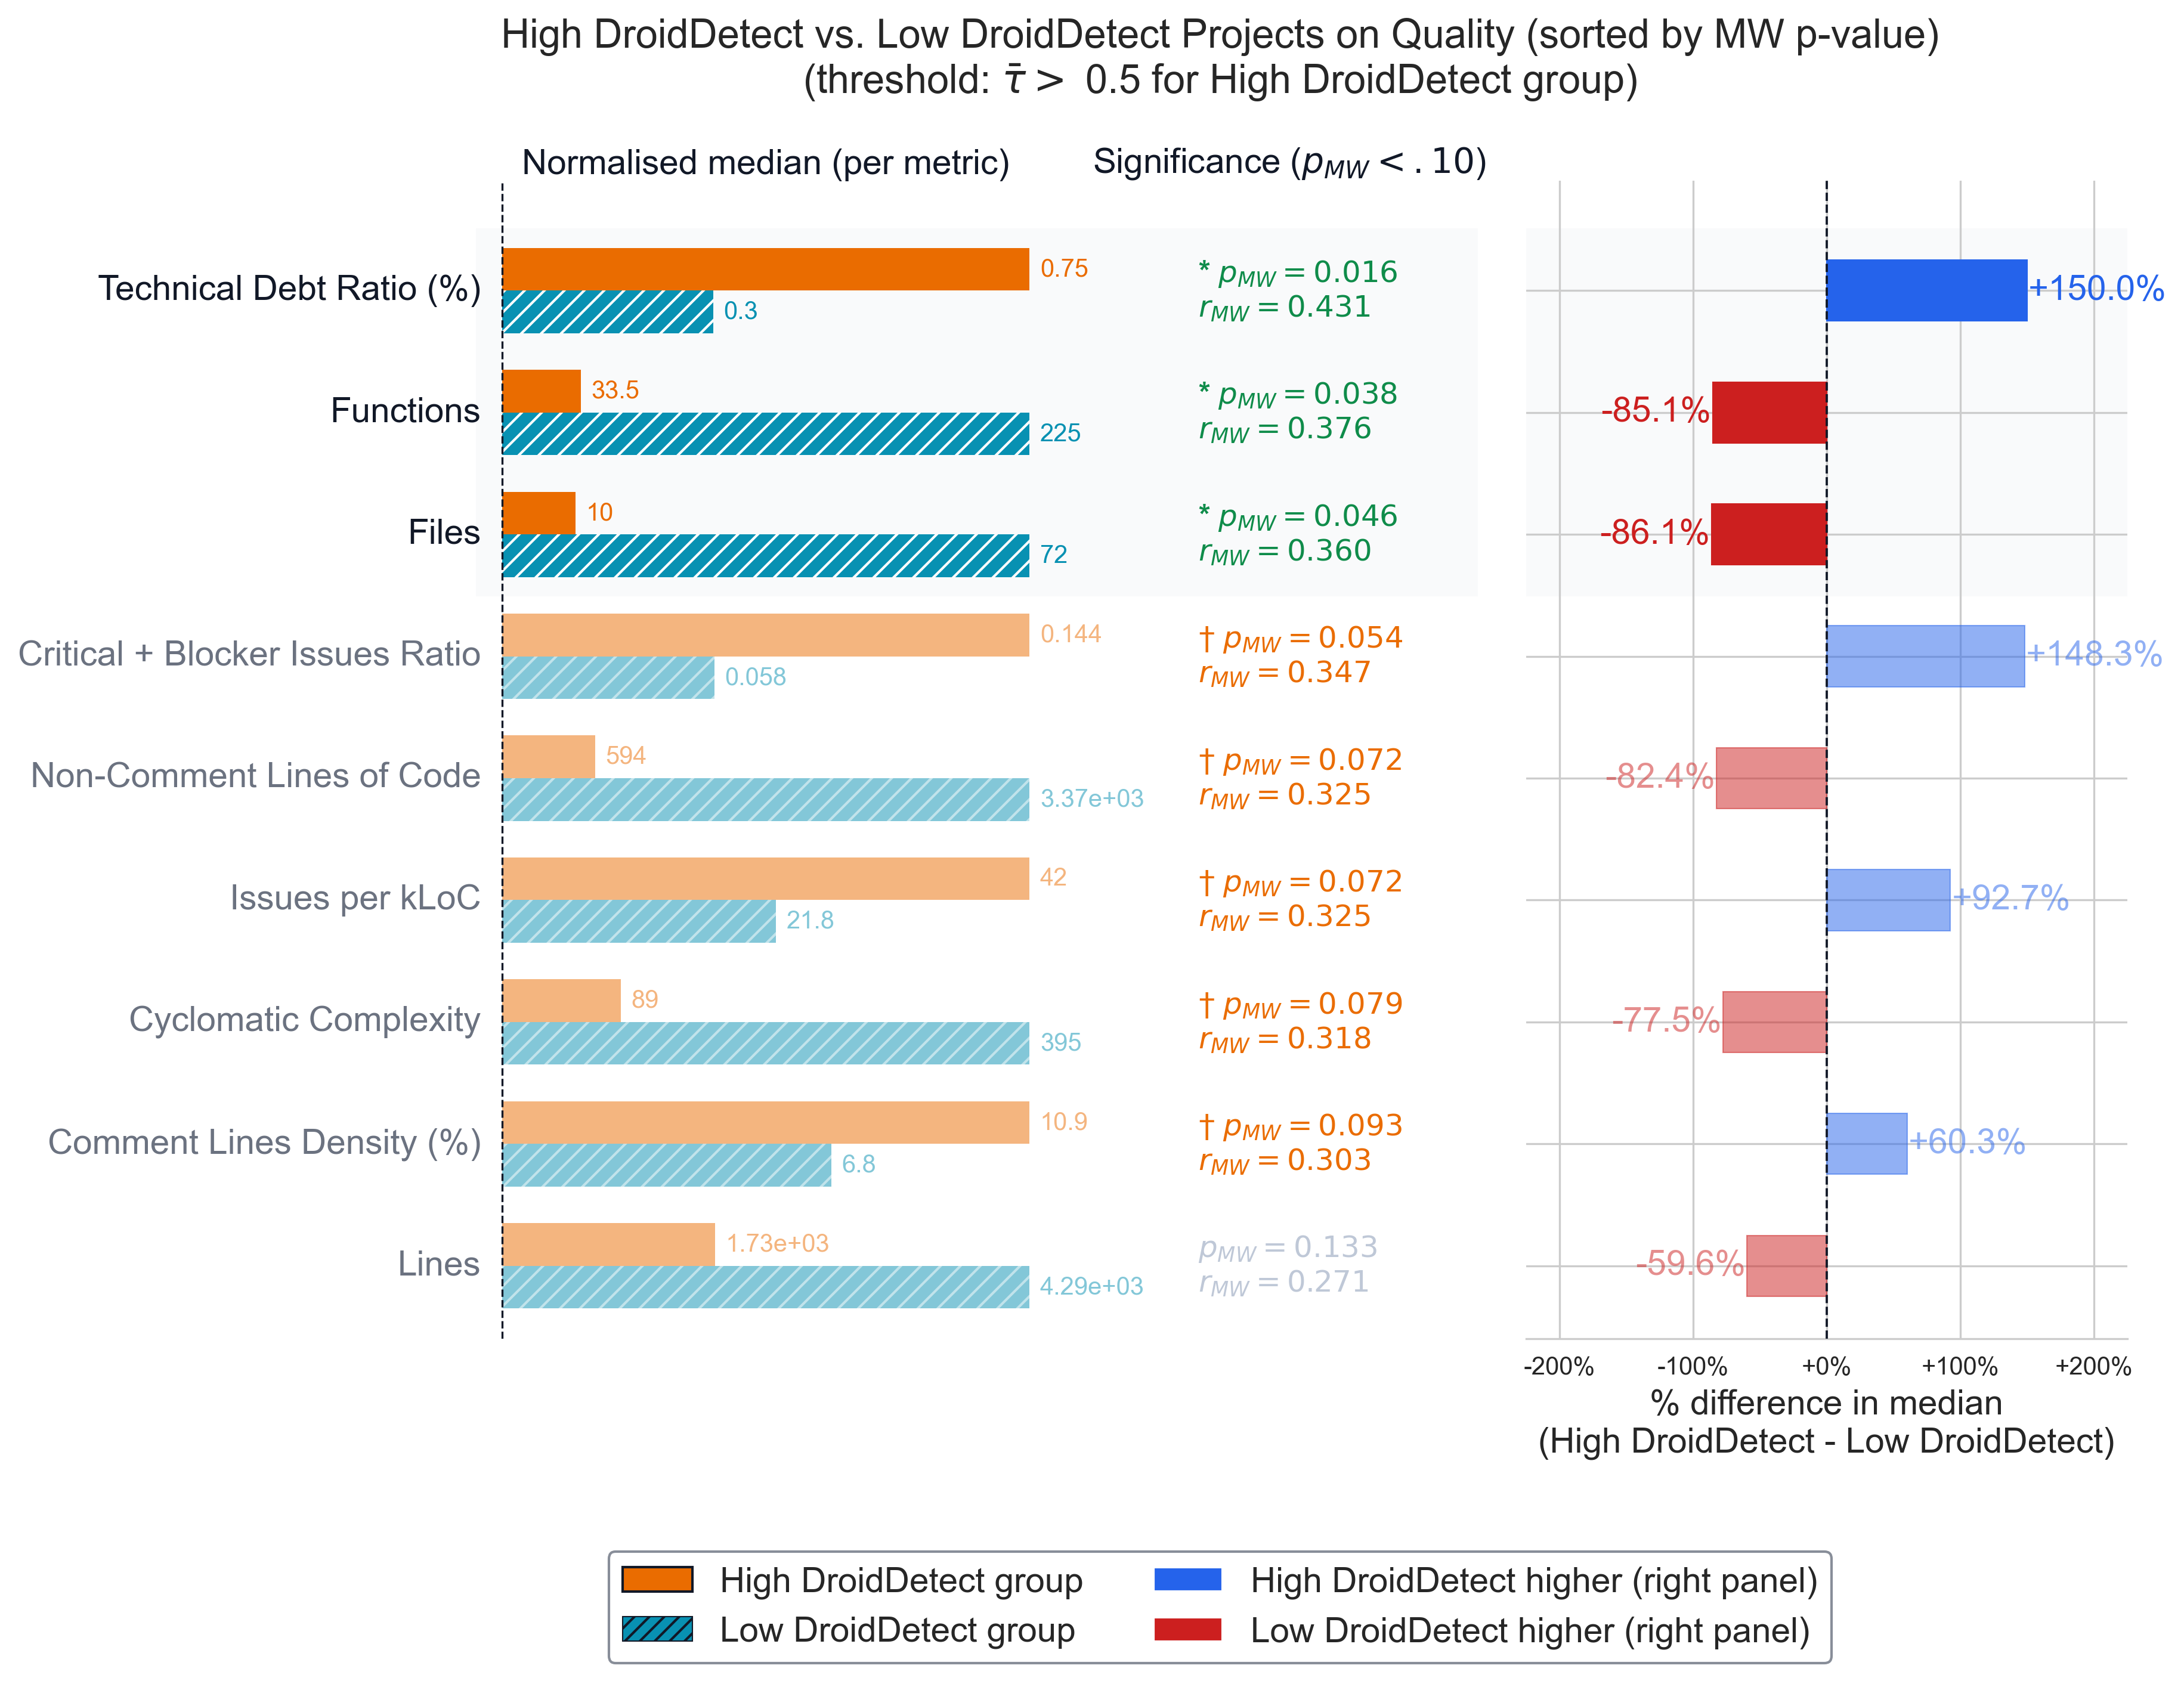

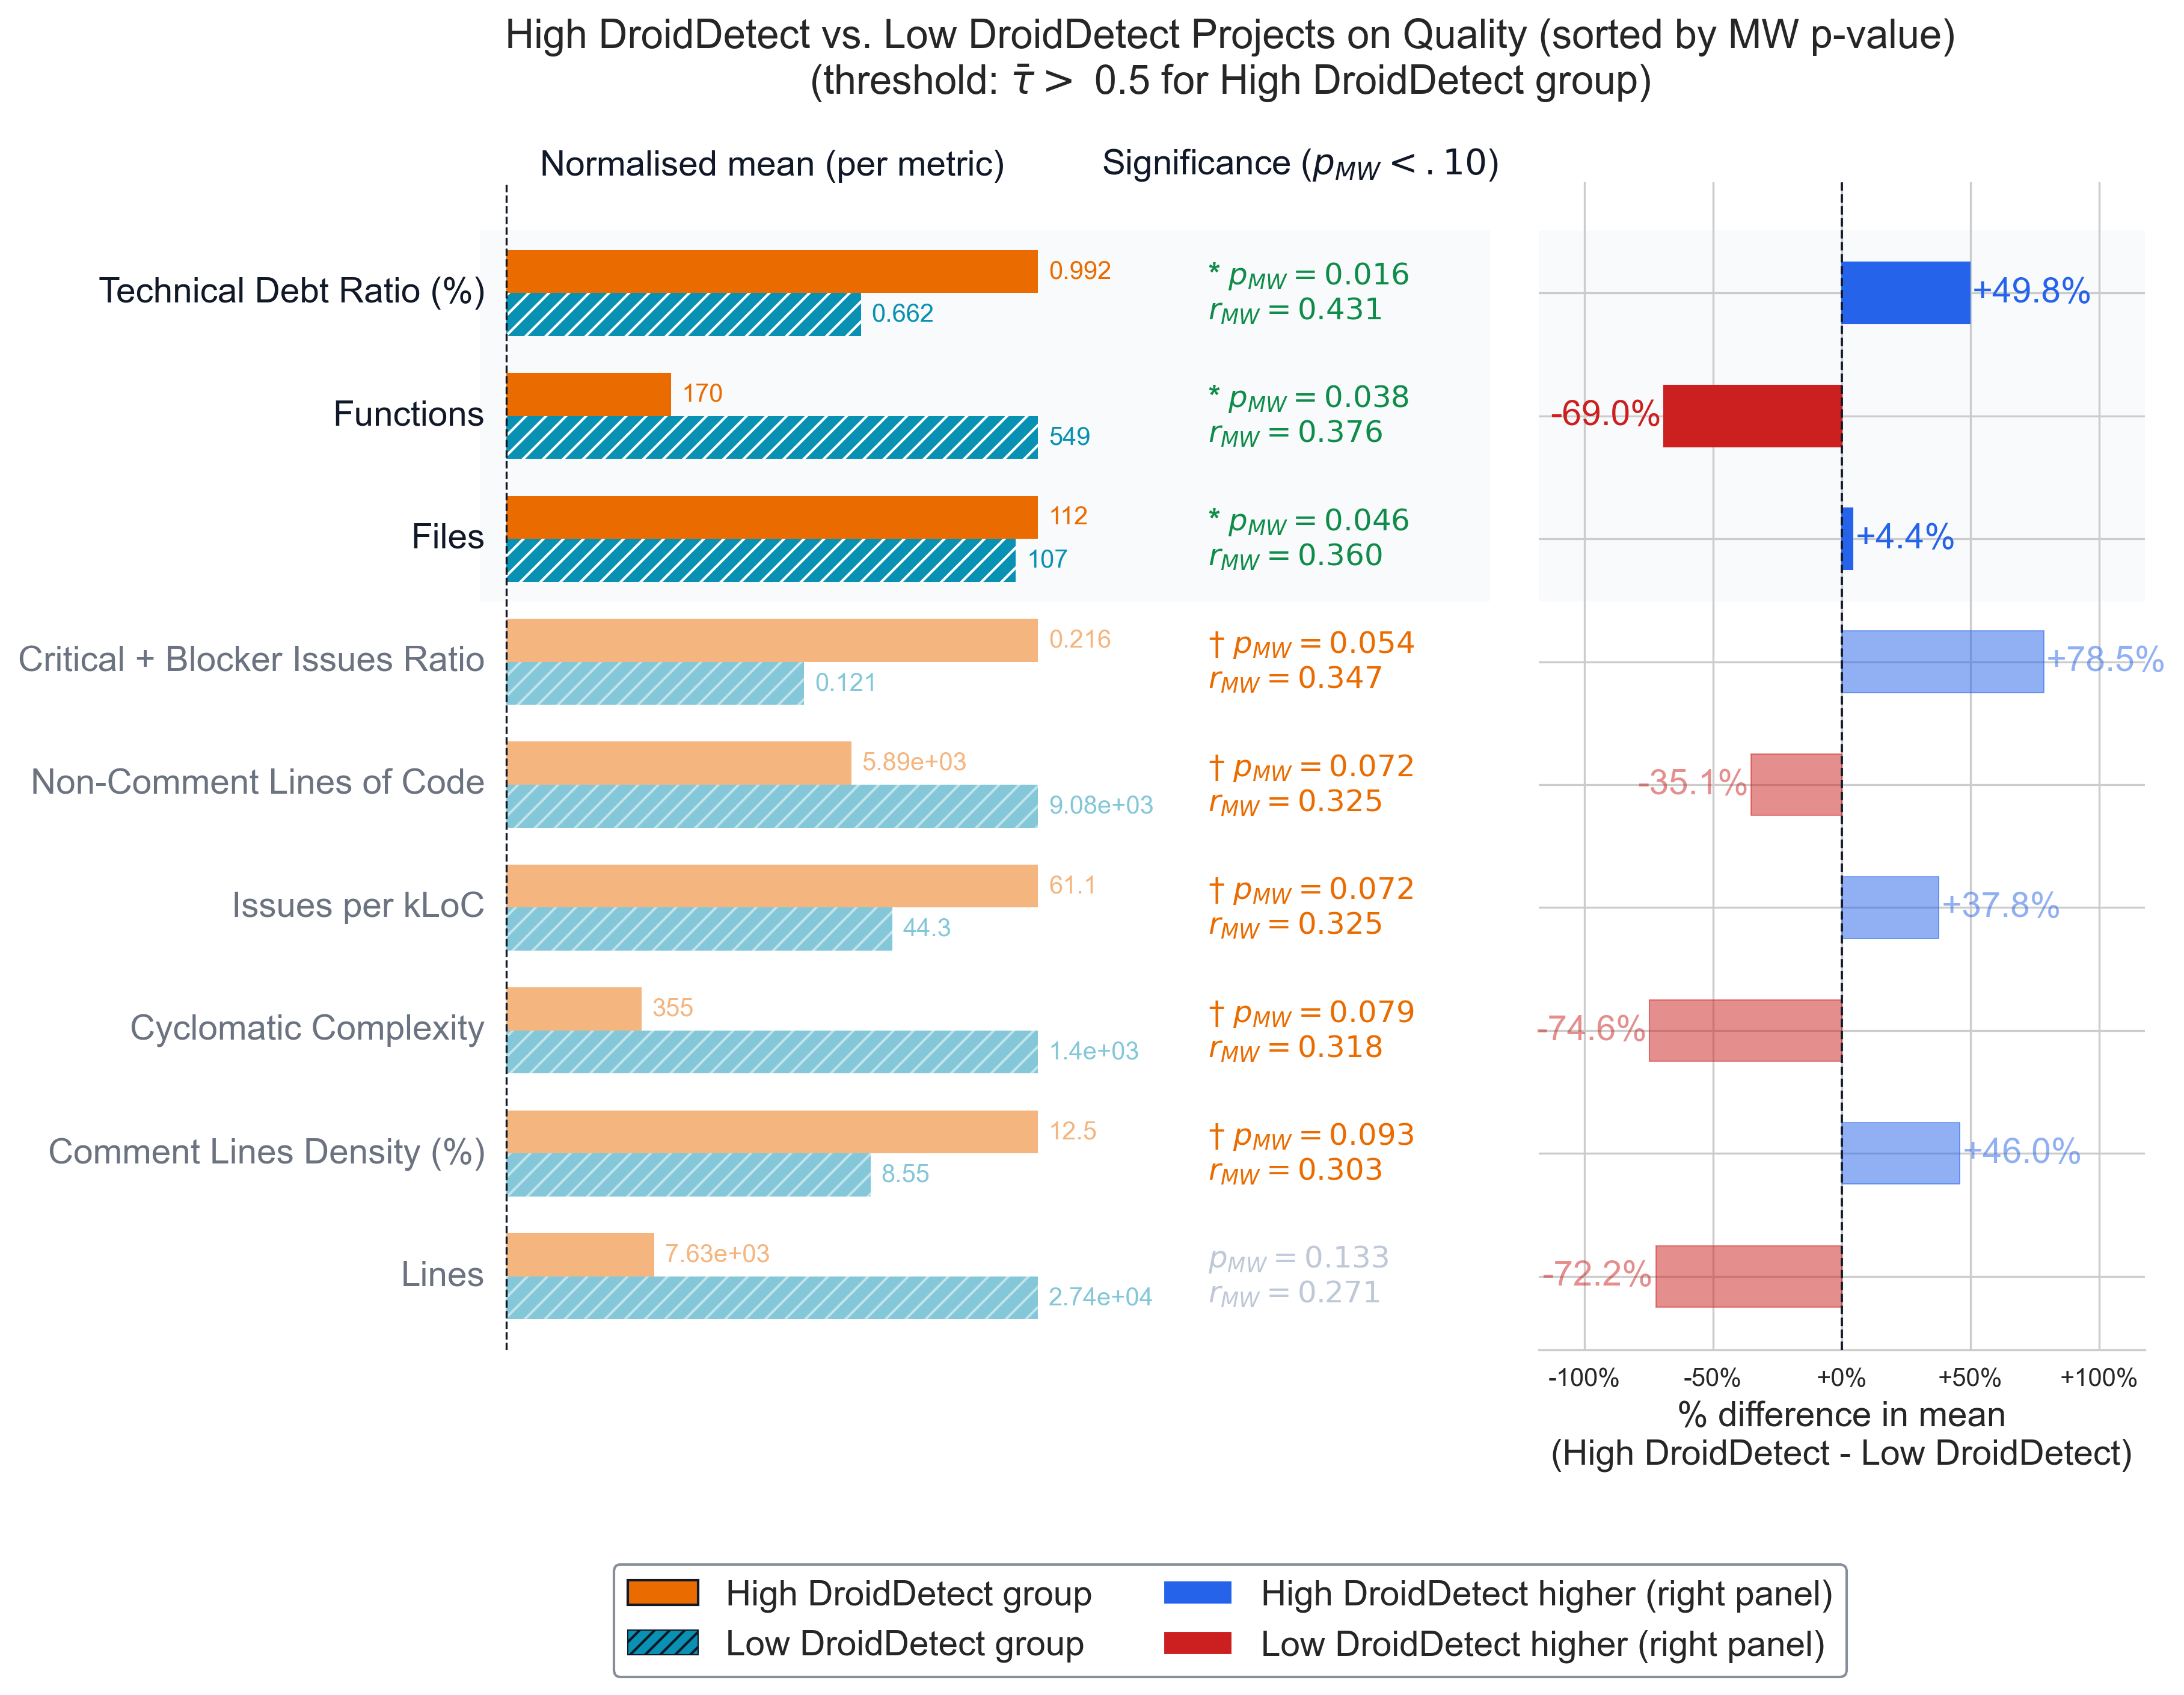

In [17]:
significant_columns = df[df["p_mw(quality|high_machine_droiddetect)"] < 0.1]["metric"].tolist()
additional = ["lines"]
remove = ["n_blocker"]

combined = (set(significant_columns) | set(additional)) - set(remove)

display(df[df["metric"].isin(combined)])
visualize_mw_results(df[df["metric"].isin(combined)], high_threshold, measure="median", save_path="overleaf/H3_1.pdf")
visualize_mw_results(df[df["metric"].isin(combined)], high_threshold, measure="mean")


In [18]:
print_df = df[df["metric"].isin(combined)].copy()

In [19]:
print_df["metric"] = print_df["metric"].map(
    lambda m: METRIC_LABELS.get(m, m.replace("_", " ").title())
)

FEATURES_LABELS = {
    "mean_quality(high_machine_droiddetect)": "Mean (High)",
    "p_mw(quality|high_machine_droiddetect)": "$p_{MW}$",
    "median_quality(high_machine_droiddetect)": "Median (High)",
    "mean_quality(low_machine_droiddetect)": "Mean (Low)",
    "median_quality(low_machine_droiddetect)": "Median (Low)",
    "U(quality|high_machine_droiddetect)": "$U_{High}$",
    "U(quality|low_machine_droiddetect)": "$U_{Low}$",
    "r_mw(quality|high_machine_droiddetect)": "$r_{MW}$",
}

FEATURE_ORDER = [
    "metric",
    "mean_quality(low_machine_droiddetect)",
    "median_quality(low_machine_droiddetect)",
    "U(quality|low_machine_droiddetect)",
    "mean_quality(high_machine_droiddetect)",
    "median_quality(high_machine_droiddetect)",
    "U(quality|high_machine_droiddetect)",
    "p_mw(quality|high_machine_droiddetect)",
    "r_mw(quality|high_machine_droiddetect)",
]

print_df = print_df[FEATURE_ORDER]
print_df.rename(columns=FEATURES_LABELS, inplace=True)

print_df.sort_values("$p_{MW}$", inplace=True)

print(print_df.to_latex(index=False, float_format="%.3f"))

\begin{tabular}{lrrrrrrrr}
\toprule
metric & Mean (Low) & Median (Low) & $U_{Low}$ & Mean (High) & Median (High) & $U_{High}$ & $p_{MW}$ & $r_{MW}$ \\
\midrule
Technical Debt Ratio (%) & 0.662 & 0.300 & 266.500 & 0.992 & 0.750 & 669.500 & 0.016 & 0.431 \\
Functions & 549.093 & 225.000 & 619.000 & 170.250 & 33.500 & 281.000 & 0.038 & 0.376 \\
Files & 107.321 & 72.000 & 636.500 & 112.000 & 10.000 & 299.500 & 0.046 & 0.360 \\
Critical + Blocker Issues Ratio & 0.121 & 0.058 & 305.500 & 0.216 & 0.144 & 630.500 & 0.054 & 0.347 \\
Issues per kLoC & 44.329 & 21.806 & 316.000 & 61.090 & 42.013 & 620.000 & 0.072 & 0.325 \\
Non-Comment Lines of Code & 9083.154 & 3366.500 & 620.000 & 5893.667 & 593.500 & 316.000 & 0.072 & 0.325 \\
Cyclomatic Complexity & 1397.893 & 395.000 & 593.000 & 355.083 & 89.000 & 307.000 & 0.079 & 0.318 \\
Comment Lines Density (%) & 8.547 & 6.800 & 326.000 & 12.475 & 10.900 & 610.000 & 0.093 & 0.303 \\
Lines & 27413.718 & 4293.500 & 595.000 & 7632.333 & 1734.500 & 341.000 

In [20]:
analysis_df = pd.merge(
    aiup_final_product,
    sqp_final_product,
    on="repository_id",
)

# print(analysis_df.columns)
# print(analysis_df.shape)

aiup_ids = set(aiup_final_product['repository_id'])
sqp_ids  = set(sqp_final_product['repository_id'])

in_aiup_not_sqp = aiup_ids - sqp_ids
in_sqp_not_aiup = sqp_ids - aiup_ids
in_both         = aiup_ids & sqp_ids

print(f"Total in AIUP: {len(aiup_ids)}")
print(f"Total in SQP: {len(sqp_ids)}")
print(f"In AIUP but not SQP ({len(in_aiup_not_sqp)}): {in_aiup_not_sqp}")
print(f"In SQP but not AIUP ({len(in_sqp_not_aiup)}): {in_sqp_not_aiup}")
print(f"In both ({len(in_both)})")

Total in AIUP: 91
Total in SQP: 91
In AIUP but not SQP (1): {'2020_Kundestyrt-Gruppe-10_Purefolio-backend'}
In SQP but not AIUP (1): {'2018_TDT4290-CiDev_api-gateway'}
In both (90)


In [21]:
def plot_buckets_per_metric(
    df,
    bucket_col,
    only_show_significant=True,
    skip_cols=[],
    figsize_scale=1.0,
    show_points=True,
    save_path=None,
):
    def _label(m):
        return METRIC_LABELS.get(m, m.replace("_", " ").title())

    # ── 1. select numeric metrics ─────────────────────────────────────────────
    exclude = {"repository_id", bucket_col} | set(skip_cols)
    metrics = [c for c in df.select_dtypes(include="number").columns if c not in exclude]
    if not metrics:
        raise ValueError("No numeric metrics found after exclusions.")

    order = ["Low", "Medium", "High"]
    buckets = df[bucket_col].dropna().unique()
    buckets = [b for b in order if b in buckets]

    n_buckets = len(buckets)

    color_map = {"Low": C_GREEN, "Medium": C_ORANGE, "High": C_RED}
    bucket_xs = np.arange(n_buckets)

    # ── 2. per-metric stats ───────────────────────────────────────────────────
    metric_stats = {}
    for m in metrics:
        groups  = [df.loc[df[bucket_col] == b, m].dropna().values for b in buckets]
        medians = np.array([np.median(g) if len(g) else np.nan for g in groups])
        spread  = (np.nanmax(medians) - np.nanmin(medians)) if not np.all(np.isnan(medians)) else 0.0
        valid_groups = [g for g in groups if len(g) >= 2]
        p_val = stats.kruskal(*valid_groups)[1] if len(valid_groups) >= 2 else np.nan
        metric_stats[m] = {"groups": groups, "medians": medians, "spread": spread, "kruskal_p": p_val}

    # ── 3. filter metrics ─────────────────────────────────────────────────────
    if only_show_significant:
        filtered_metrics = [m for m in metrics if metric_stats[m]["kruskal_p"] < 0.05]
    else:
        filtered_metrics = metrics

    sorted_metrics = sorted(
        filtered_metrics,
        key=lambda m: metric_stats[m]["kruskal_p"] if not np.isnan(metric_stats[m]["kruskal_p"]) else -1,
    )

    # ── 4. create figures split into tables of max 4 rows ────────────────────
    n_cols = 3
    metrics_per_table = 4 * n_cols

    num_tables = math.ceil(len(sorted_metrics) / metrics_per_table)

    final_df = []

    for table_idx in range(num_tables):
        start_idx = table_idx * metrics_per_table
        end_idx = min(start_idx + metrics_per_table, len(sorted_metrics))
        table_metrics = sorted_metrics[start_idx:end_idx]

        t_rows = math.ceil(len(table_metrics) / n_cols)

        fig_w = 6 * n_cols * figsize_scale
        fig_h = 4.0 * t_rows * figsize_scale
        fig, axes = plt.subplots(t_rows, n_cols, figsize=(fig_w, fig_h), facecolor=C_ROW, dpi=600)
        axes = np.array(axes).reshape(-1)

        for idx, m in enumerate(table_metrics):
            ax = axes[idx]
            stat = metric_stats[m]
            p_val = stat["kruskal_p"]

            ax.set_facecolor(C_ROW)

            for xi, (b, grp) in enumerate(zip(buckets, stat["groups"])):
                if len(grp) == 0:
                    continue
                vals = grp
                q1, med, q3 = np.percentile(vals, [25, 50, 75])
                iqr = q3 - q1
                lo = max(vals.min(), q1 - 1.5 * iqr)
                hi = min(vals.max(), q3 + 1.5 * iqr)
                vals = vals[(vals >= lo) & (vals <= hi)]

                final_df.append({
                    "metric": m,
                    "bucket": b,
                    "median": med,
                    "p_val": p_val,
                })

                if len(vals) == 0:
                    continue

                box_w = 0.55
                color = color_map[b]

                ax.add_patch(plt.Rectangle((xi - box_w / 2, q1), box_w, iqr,
                                           facecolor=color, alpha=0.25, edgecolor=color, linewidth=0.8))
                ax.hlines(med, xi - box_w / 2, xi + box_w / 2, color=color, linewidth=1.8)

                cap_w = box_w * 0.5
                ax.vlines(xi, lo, q1, color=color, linewidth=0.8)
                ax.hlines(lo, xi - cap_w / 2, xi + cap_w / 2, color=color, linewidth=0.8)
                ax.vlines(xi, q3, hi, color=color, linewidth=0.8)
                ax.hlines(hi, xi - cap_w / 2, xi + cap_w / 2, color=color, linewidth=0.8)

                if show_points and len(vals) <= 300:
                    jitter = np.random.default_rng(42).uniform(-0.18, 0.18, len(vals))
                    ax.scatter(xi + jitter, vals, s=6, color=color, alpha=0.35, linewidths=0)
                ax.scatter(xi, np.mean(vals), marker="D", s=18, color=color,
                           edgecolors="white", linewidths=0.6)

            ax.set_xlim(-0.6, n_buckets - 0.4)
            ax.set_xticks(bucket_xs)
            ax.set_xticklabels([str(b) for b in buckets], fontsize=12, color=C_TEXT)
            ax.tick_params(axis="y", labelsize=12, labelcolor=C_TEXT, length=2)
            ax.tick_params(axis="x", length=0)
            ax.grid(axis="y", color=C_ROW_SHADING, linewidth=0.5)

            # Compute significance markers and color
            sig = "" if np.isnan(p_val) else (
                "***" if p_val < 0.001 else "**" if p_val < 0.01 else "*" if p_val < 0.05 else ""
            )
            p_str = "{:.4f}".format(p_val)
            sig_color = C_SIG if (not np.isnan(p_val) and p_val < 0.05) else C_TEXT_NS

            # Metric name — large, bold, left side
            ax.set_title(_label(m), fontsize=14, fontweight="bold",
                         color=C_TEXT, pad=8, loc="left")

            # p-value — same line as title, right side, color-coded by significance
            ax.text(1.0, 1.02, f"{sig} $p_{{KW}} = {p_str}$",
                    transform=ax.transAxes,
                    fontsize=14, fontweight="bold",
                    color=sig_color,
                    ha="right", va="bottom")

        # Hide unused axes in this figure
        for idx in range(len(table_metrics), len(axes)):
            axes[idx].set_visible(False)

        fig.tight_layout(rect=[0, 0, 1, 0.94])
        fig.suptitle(
            r"Low, Medium, and High AI usage compared by Kruskal-Wallis p-values ($p_{KW}$)",
            fontsize=16, color=C_TEXT, y=0.98,
        )
        if save_path:
            fig.savefig(save_path, format="pdf", bbox_inches="tight")

        plt.show()

    final_df = pd.DataFrame(final_df)
    return sorted_metrics, final_df

In [22]:
import pandas as pd
import numpy as np
from scipy import stats
from itertools import combinations

def mw_posthoc_bonferroni(df, metric_col, bucket_col):
    """
    Conduct pairwise Mann-Whitney U tests between bucket groups for a given metric.
    Applies Bonferroni correction for multiple comparisons.

    Parameters
    ----------
    df : pd.DataFrame
        Data containing the metric and bucket columns.
    metric_col : str
        Name of the metric column to test.
    bucket_col : str
        Name of the categorical bucket column (should be sorted: low → medium → high).

    Returns
    -------
    pd.DataFrame
        Pairwise comparisons with U statistic, raw p-value, and Bonferroni-adjusted p-value.
    """
    # Get unique buckets in sorted order
    buckets = df[bucket_col].dropna().unique()
    n_comparisons = len(buckets) * (len(buckets) - 1) // 2
    
    results = []
    for b1, b2 in combinations(buckets, 2):
        group1 = df.loc[df[bucket_col] == b1, metric_col].dropna()
        group2 = df.loc[df[bucket_col] == b2, metric_col].dropna()
        
        if len(group1) < 1 or len(group2) < 1:
            u_group_1, u_group_2, p_val = np.nan, np.nan, np.nan
            r_mw = np.nan
        else:
            u_group_1, p_val = stats.mannwhitneyu(group1, group2, alternative='two-sided')
            u_group_2 = len(group1) * len(group2) - u_group_1
            u_min = min(u_group_1, u_group_2)
            r_mw = 1 - (2 * u_min) / (len(group1) * len(group2))
            
            
        p_adj = min(p_val * n_comparisons, 1.0) if not np.isnan(p_val) else np.nan
        
        results.append({
            "metric": metric_col,
            "group1": b1,
            "mean1": group1.mean() if len(group1) > 0 else np.nan,
            "median1": group1.median() if len(group1) > 0 else np.nan,
            "group2": b2,
            "mean2": group2.mean() if len(group2) > 0 else np.nan,
            "median2": group2.median() if len(group2) > 0 else np.nan,
            "U_group1": u_group_1,
            "U_group2": u_group_2,
            "effect_size": r_mw,
            "p_mw": p_val,
            "p_mw_bonferroni": p_adj
        })
    
    return pd.DataFrame(results)

In [23]:

def split_into_buckets(df, split_feature, medium_threshold=0.4, high_threshold=0.6):
    # Create quantile-based buckets
    df[f"{split_feature}_bucket"] = pd.cut(df[split_feature], bins=[0, medium_threshold, high_threshold, 1], labels=[f"Low", f"Medium", f"High"])
    return df

In [24]:
split_features = "prob_machine_droiddetect_mean"

skip_cols = list(aiup_final_product.columns) + ["coverage"]

medium_threshold = 0.4
high_threshold = 0.6
df = split_into_buckets(analysis_df, split_features, medium_threshold=medium_threshold, high_threshold=high_threshold)

print(f"Buckets for {split_features}:")
print(df[f"{split_features}_bucket"].value_counts())
sorted_metrics, metrics_df = plot_buckets_per_metric(df, bucket_col=f"{split_features}_bucket", skip_cols=skip_cols, only_show_significant=True, save_path="overleaf/H3_3.pdf")
print("SHOWING RESULTS FOR " + split_features)
final_df = []

for metric in sorted_metrics:
    result_df = mw_posthoc_bonferroni(df, metric, f"{split_features}_bucket")
    final_df.append(result_df)

final_df = pd.concat(final_df, ignore_index=True)
display(final_df)

print("SHOWING METRICS WITH SIGNIFICANT KRUSKAL-WALLIS TESTS")
display(metrics_df)

Buckets for prob_machine_droiddetect_mean:
prob_machine_droiddetect_mean_bucket
Low       64
Medium    22
High       4
Name: count, dtype: int64


SHOWING RESULTS FOR prob_machine_droiddetect_mean


,metric,group1,mean1,median1,group2,mean2,median2,U_group1,U_group2,effect_size,p_mw,p_mw_bonferroni
0,functions,Low,641.786885,272.000000,High,95.750000,62.500000,195.0,49.0,0.598361,0.047803,0.143409
1,functions,Low,641.786885,272.000000,Medium,167.863636,119.000000,951.5,390.5,0.418033,0.003865,0.011595
2,functions,High,95.750000,62.500000,Medium,167.863636,119.000000,42.0,46.0,0.045455,0.915092,1.000000
3,files,Low,119.703125,74.000000,High,219.250000,18.500000,180.0,76.0,0.406250,0.179458,0.538373
4,files,Low,119.703125,74.000000,Medium,53.500000,37.500000,998.5,409.5,0.418324,0.003610,0.010831
5,files,High,219.250000,18.500000,Medium,53.500000,37.500000,42.0,46.0,0.045455,0.914990,1.000000
6,complexity,Low,1654.983607,451.000000,High,256.750000,107.500000,185.0,59.0,0.516393,0.087987,0.263960
7,complexity,Low,1654.983607,451.000000,Medium,323.727273,211.000000,927.0,415.0,0.381520,0.008384,0.025152
8,complexity,High,256.750000,107.500000,Medium,323.727273,211.000000,43.0,45.0,0.022727,0.972575,1.000000
9,ncloc,Low,10541.859375,3900.500000,High,12087.250000,712.000000,178.0,78.0,0.390625,0.205421,0.616264


SHOWING METRICS WITH SIGNIFICANT KRUSKAL-WALLIS TESTS


,metric,bucket,median,p_val
0,functions,Low,272.000000,0.004208
1,functions,Medium,119.000000,0.004208
2,functions,High,62.500000,0.004208
3,files,Low,74.000000,0.008576
4,files,Medium,37.500000,0.008576
5,files,High,18.500000,0.008576
6,complexity,Low,451.000000,0.011956
7,complexity,Medium,211.000000,0.011956
8,complexity,High,107.500000,0.011956
9,ncloc,Low,3900.500000,0.017677


In [25]:
def df_to_multirow_latex(df, metric_col="metric", p_col="p_mw_bonferroni"):

    df = df.copy()

    # Apply metric labels
    df[metric_col] = df[metric_col].map(
        lambda m: METRIC_LABELS.get(m, m.replace("_", " ").title())
    )

    # Compute % differences
    df["delta_mean_pct"]   = ((df["mean2"]   - df["mean1"])   / df["mean1"].abs().replace(0, np.nan)   * 100).round(1)
    df["delta_median_pct"] = ((df["median2"] - df["median1"]) / df["median1"].abs().replace(0, np.nan) * 100).round(1)

    df["delta_mean_pct"]   = df["delta_mean_pct"].apply(
        lambda x: f"{x:+.1f}\\%" if not np.isnan(x) else "N/A"
    )
    df["delta_median_pct"] = df["delta_median_pct"].apply(
        lambda x: f"{x:+.1f}\\%" if not np.isnan(x) else "N/A"
    )

    # Bold significant Bonferroni p-values
    df[p_col] = df[p_col].apply(
        lambda p: f"\\textbf{{{p:.3f}}}" if p < 0.05 else f"{p:.3f}"
    )

    df = df.drop(columns=["p_mw"])

    metrics = df[metric_col].unique()

    lines = []
    lines.append("\\begin{landscape}")
    lines.append("\\begin{table}[H]")
    lines.append("    \\scriptsize")
    lines.append("    \\centering")
    lines.append("    \\begin{tabular}{ll@{\\hspace{2em}}rr@{\\hspace{2em}}rr@{\\hspace{2em}}rrrr}")
    lines.append("    \\toprule")
    lines.append("    & & \\multicolumn{2}{c}{Group 1} & \\multicolumn{2}{c}{Group 2} & & & & \\\\")
    lines.append("    \\cmidrule(lr){3-4} \\cmidrule(lr){5-6}")
    lines.append("    Metric & Comparison & Mean & Median & Mean & Median & $\\Delta Mean (\\%)$ & $\\Delta Median (\\%)$ & $r_{MW}$ & $p_{MW,Bonf}$ \\\\")
    lines.append("    \\midrule")

    for metric in metrics:
        subset = df[df[metric_col] == metric].reset_index(drop=True)
        n = len(subset)

        for j, row in subset.iterrows():
            comparison   = f"{row['group1']} vs {row['group2']}"
            mean1        = f"{row['mean1']:.3f}"
            median1      = f"{row['median1']:.3f}"
            mean2        = f"{row['mean2']:.3f}"
            median2      = f"{row['median2']:.3f}"
            delta_mean   = row["delta_mean_pct"]
            delta_median = row["delta_median_pct"]
            r            = f"{row['effect_size']:.3f}"
            p            = row[p_col]

            if j == 0:
                metric_cell = f"\\multirow{{{n}}}{{*}}{{{metric}}}"
            else:
                metric_cell = ""

            # Put rowcolor AFTER multirow so it doesn't interfere with the spanning cell
            if "\\textbf" in p:
                row_line = f"    {metric_cell} & \\cellcolor{{green!15}}{comparison} & \\cellcolor{{green!15}}{mean1} & \\cellcolor{{green!15}}{median1} & \\cellcolor{{green!15}}{mean2} & \\cellcolor{{green!15}}{median2} & \\cellcolor{{green!15}}{delta_mean} & \\cellcolor{{green!15}}{delta_median} & \\cellcolor{{green!15}}{r} & \\cellcolor{{green!15}}{p} \\\\"
            else:
                row_line = f"    {metric_cell} & {comparison} & {mean1} & {median1} & {mean2} & {median2} & {delta_mean} & {delta_median} & {r} & {p} \\\\"

            lines.append(row_line)

        lines.append("    \\midrule")

    lines[-1] = "    \\bottomrule"

    lines.append("    \\end{tabular}")
    lines.append("    \\caption{Post-hoc pairwise Mann-Whitney U comparisons with Bonferroni correction across AI usage groups (Low, Medium, High). Group 1 and Group 2 refer to the first and second named group in the Comparison column respectively. $\\Delta Mean (\\%)$ and $\\Delta Median (\\%)$ denote the percentage change from Group 1 to Group 2. Effect size $r_{MW}$ is computed using the Wendt formula \\cite{wendt1972rank}. Bonferroni-adjusted p-values ($p_{MW,Bonf}$) significant at $p < 0.05$ are shown in \\textbf{bold} and rows are highlighted in green. The unadjusted $p_{MW}$ is omitted in favour of the corrected value.}")
    lines.append("    \\label{tab:H3_posthoc}")
    lines.append("\\end{table}")
    lines.append("\\end{landscape}")

    return "\n".join(lines)

print(df_to_multirow_latex(final_df))

\begin{landscape}
\begin{table}[H]
    \scriptsize
    \centering
    \begin{tabular}{ll@{\hspace{2em}}rr@{\hspace{2em}}rr@{\hspace{2em}}rrrr}
    \toprule
    & & \multicolumn{2}{c}{Group 1} & \multicolumn{2}{c}{Group 2} & & & & \\
    \cmidrule(lr){3-4} \cmidrule(lr){5-6}
    Metric & Comparison & Mean & Median & Mean & Median & $\Delta Mean (\%)$ & $\Delta Median (\%)$ & $r_{MW}$ & $p_{MW,Bonf}$ \\
    \midrule
    \multirow{3}{*}{Functions} & Low vs High & 641.787 & 272.000 & 95.750 & 62.500 & -85.1\% & -77.0\% & 0.598 & 0.143 \\
     & \cellcolor{green!15}Low vs Medium & \cellcolor{green!15}641.787 & \cellcolor{green!15}272.000 & \cellcolor{green!15}167.864 & \cellcolor{green!15}119.000 & \cellcolor{green!15}-73.8\% & \cellcolor{green!15}-56.2\% & \cellcolor{green!15}0.418 & \cellcolor{green!15}\textbf{0.012} \\
     & High vs Medium & 95.750 & 62.500 & 167.864 & 119.000 & +75.3\% & +90.4\% & 0.045 & 1.000 \\
    \midrule
    \multirow{3}{*}{Files} & Low vs High & 119.703 & 74.000

In [26]:
def plot_post_hoc_df(post_hoc_df, use_bonferroni=True, save_path=None):

    p_col   = "p_mw_bonferroni" if use_bonferroni else "p_mw"
    p_label = "Bonferroni-adjusted $p_{MW}$" if use_bonferroni else "$p_{MW}$"

    # Stacked vertically: 2 rows, 1 column
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 11), dpi=300)
    fig.suptitle(
        f"Post-hoc Pairwise Mann-Whitney U "
        f"({'Bonferroni-corrected' if use_bonferroni else 'Uncorrected'})",
        fontsize=16, color=C_TEXT,
    )

    # ── setup ───────────────────────────────────────────────────────────────
    pairs   = post_hoc_df[["group1", "group2"]].drop_duplicates().values.tolist()
    metrics = list(post_hoc_df["metric"].unique())

    x       = np.arange(len(metrics))
    width   = 0.22
    offsets = np.linspace(-width, width, len(pairs))

    colors  = [C_AI, C_ORANGE, C_GREEN]

    pair_styles = {
        (g1, g2): {"color": colors[i % len(colors)], "hatch": CATEGORY_HATCHES[i % len(CATEGORY_HATCHES)]}
        for i, (g1, g2) in enumerate(pairs)
    }

    # ── 1. Effect sizes ─────────────────────────────────────────────────────
    for idx, (g1, g2) in enumerate(pairs):

        sub = post_hoc_df[
            (post_hoc_df["group1"] == g1) &
            (post_hoc_df["group2"] == g2)
        ].set_index("metric").reindex(metrics)

        style = pair_styles[(g1, g2)]

        ax1.bar(
            x + offsets[idx],
            sub["effect_size"],
            width,
            label=f"{g1} vs {g2}",
            color=style["color"],
            hatch=style["hatch"],
            linewidth=0.4,
            alpha=0.9,
        )

    # reference lines (Cohen's small/medium/large for rank-biserial)
    ax1.axhline(0.1, color=C_RED,    ls="--", lw=0.8)
    ax1.axhline(0.3, color=C_ORANGE, ls="--", lw=0.8)
    ax1.axhline(0.5, color=C_GREEN,  ls="--", lw=0.8)

    ax1.set_ylabel("Effect size $r$ (rank-biserial)", fontsize=14, color=C_TEXT)
    ax1.set_title("Effect sizes for pairwise Mann-Whitney U comparisons",
                  fontsize=14, color=C_TEXT, pad=8)

    ax1.set_xticks(x)
    # No xtick labels on top plot — they appear under the bottom plot
    ax1.set_xticklabels([])
    ax1.tick_params(axis="y", labelsize=12, colors=C_TEXT)
    ax1.tick_params(axis="x", length=0)

    ax1.grid(axis="y", linestyle=":", alpha=0.5)
    ax1.set_ylim(0, 0.6)

    ax1.legend(title="Group comparison", fontsize=12, title_fontsize=12, loc="upper right")

    # ── 2. -log10(p) ────────────────────────────────────────────────────────
    sig_line = -np.log10(0.05)

    for idx, (g1, g2) in enumerate(pairs):

        sub = post_hoc_df[
            (post_hoc_df["group1"] == g1) &
            (post_hoc_df["group2"] == g2)
        ].set_index("metric").reindex(metrics)

        lp = sub[p_col].apply(lambda p: -np.log10(p) if p > 0 else np.nan)

        style = pair_styles[(g1, g2)]

        ax2.bar(
            x + offsets[idx],
            lp,
            width,
            color=style["color"],
            hatch=style["hatch"],
            linewidth=0.4,
            alpha=0.9,
        )

    # significance line
    ax2.axhline(sig_line, color=C_RED, lw=1.2, linestyle="--", label="$p = 0.05$")

    # cleaner y-axis labels
    p_ticks  = [0.05, 0.01, 0.001]
    tick_pos = [-np.log10(p) for p in p_ticks]

    ax2.set_yticks(tick_pos)
    ax2.set_yticklabels([f"{p:.3f}" for p in p_ticks])

    ax2.set_ylabel(p_label, fontsize=14, color=C_TEXT)
    ax2.set_title(
        "Bonferroni-adjusted p-values" if use_bonferroni else "Unadjusted p-values",
        fontsize=14, color=C_TEXT, pad=8,
    )

    ax2.set_xticks(x)
    ax2.set_xticklabels([_label(m) for m in metrics], rotation=40, ha="right",
                        fontsize=12, color=C_TEXT)
    ax2.tick_params(axis="y", labelsize=12, colors=C_TEXT)

    ax2.grid(axis="y", linestyle=":", alpha=0.5)

    # legend (shared meaning with top plot)
    legend_handles = [
        mpatches.Patch(
            facecolor=pair_styles[(g1, g2)]["color"],
            hatch=pair_styles[(g1, g2)]["hatch"],
            label=f"{g1} vs {g2}",
        )
        for (g1, g2) in pairs
    ]
    legend_handles.append(
        Line2D([0], [0], color=C_RED, linewidth=1.2, linestyle="--", label="$p = 0.05$")
    )

    ax2.legend(handles=legend_handles, title="Group comparison",
               fontsize=12, title_fontsize=12, loc="upper right")

    plt.tight_layout(rect=[0, 0, 1, 0.96])

    if save_path:
        plt.savefig(save_path, format="pdf", bbox_inches="tight")

    plt.show()

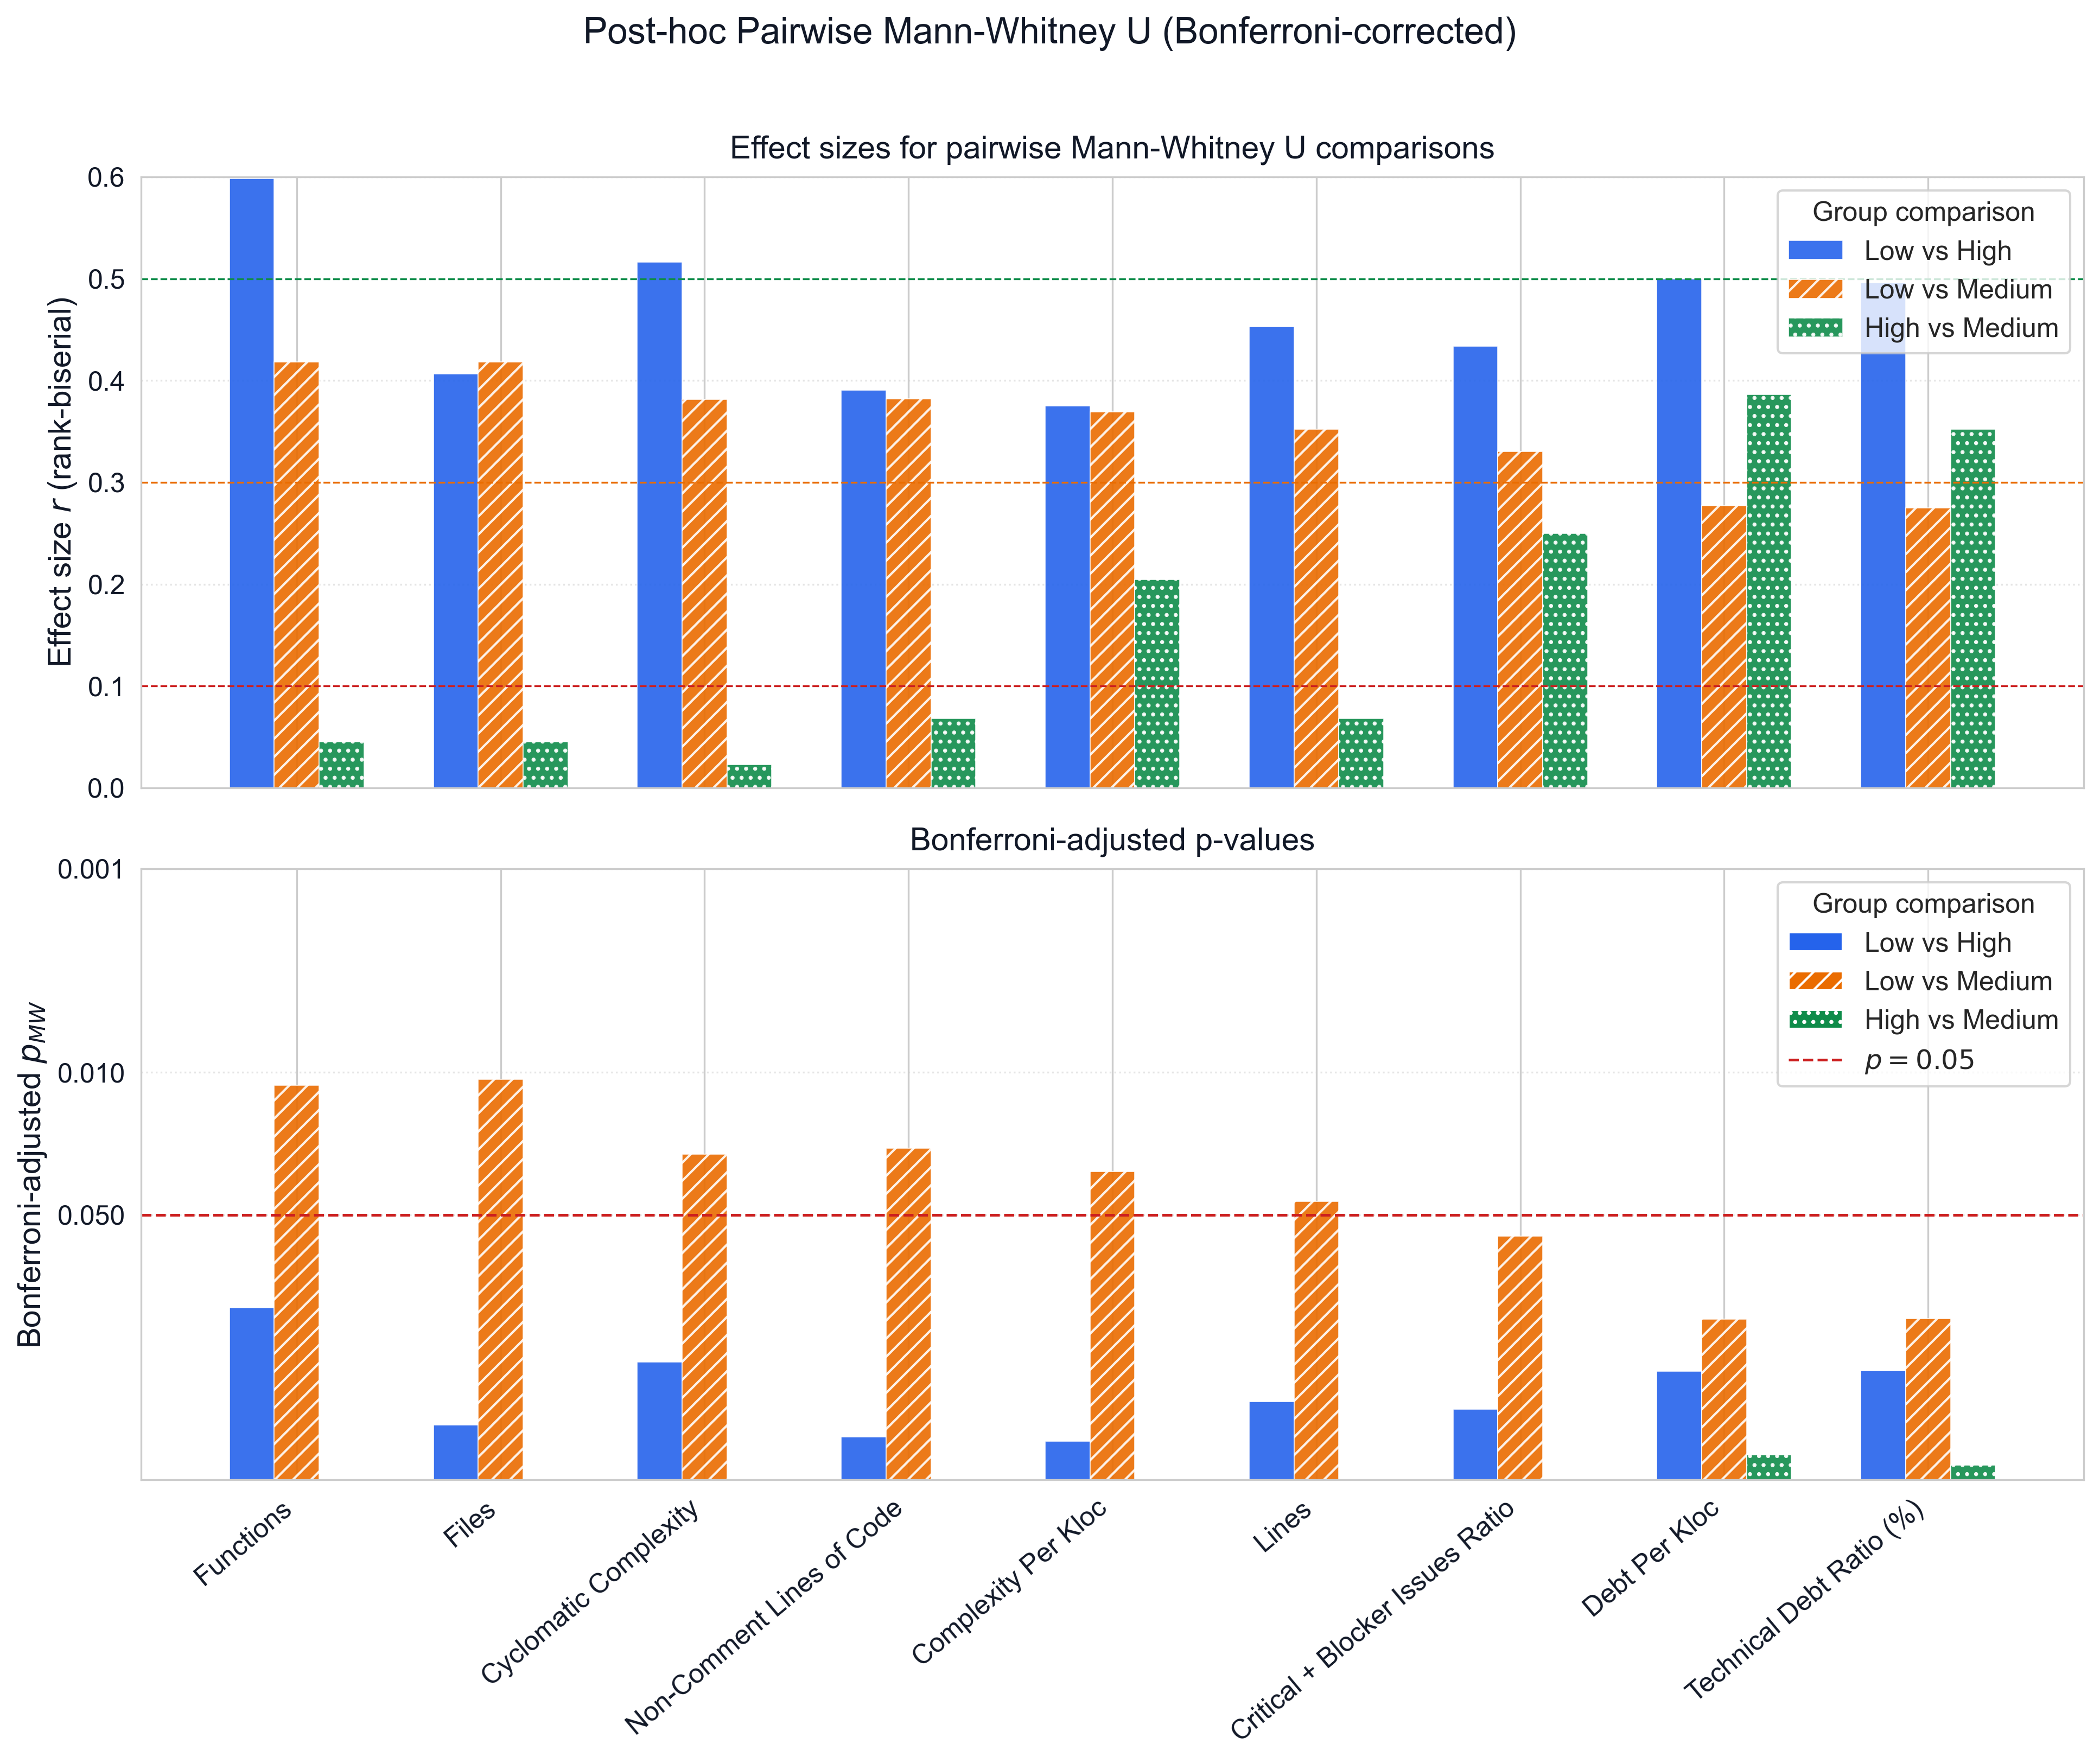

In [27]:
plot_post_hoc_df(final_df, save_path="overleaf/H3_4.pdf")